<a href="https://colab.research.google.com/github/Violetaaa/tfg-learning/blob/main/04_gis_with_python/01_geometrias_shapely.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6.1 Geometrías vectoriales con `shapely` (resumen)

Resumen del capítulo 6.1 de *Python for Geographic Data Analysis* (Tenkanen et al., pythongis.org), reducido a lo que se usa en el TFG.

**Ideas clave**
- `shapely` crea y manipula geometrías (por debajo usa la librería C++ GEOS, la misma que PostGIS y QGIS).
- GeoPandas guarda una geometría `shapely` en cada fila de la columna `geometry`. Lo que se ve aquí es lo que hay dentro de esa columna.
- Una geometría `shapely` **no tiene CRS**: son solo números. El CRS lo pone el `GeoDataFrame`.

## Tipos básicos

| Tipo | Qué es | En el TFG |
|---|---|---|
| `Point` | un par (x, y) | farmacias, centros de salud, colegios, núcleos de población |
| `LineString` | secuencia de ≥ 2 puntos | tramos de carretera (OSM) |
| `Polygon` | anillo cerrado de ≥ 3 puntos (+ huecos opcionales) | municipios, áreas de influencia (buffers) |
| `Multi*` | colección de varios del mismo tipo | p. ej. un concejo con islotes → `MultiPolygon` |

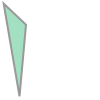

In [1]:
from shapely import Point, LineString, Polygon, MultiPoint

point = Point(2.2, 4.2)
line = LineString([(2.2, 4.2), (7.2, -25.1), (9.26, -2.456)])  # also accepts a list of Point objects
poly = Polygon([(2.2, 4.2), (7.2, -25.1), (9.26, -2.456)])     # closed automatically
multipoint = MultiPoint([Point(2, 2), Point(3, 3)])

poly  # Jupyter draws the geometry

## WKT: la representación en texto

*Well-Known Text* es el formato estándar (OGC) para escribir geometrías como texto. Es lo que verás al imprimir una geometría y lo que entienden PostGIS y QGIS. En un `POLYGON` el primer anillo es el exterior y los siguientes, si los hay, son huecos; por eso lleva doble paréntesis.

In [2]:
print(point)       # same as point.wkt
print(line.wkt)
print(poly.wkt)    # note the first coordinate is repeated at the end: the ring is closed

POINT (2.2 4.2)
LINESTRING (2.2 4.2, 7.2 -25.1, 9.26 -2.456)
POLYGON ((2.2 4.2, 7.2 -25.1, 9.26 -2.456, 2.2 4.2))


## Atributos y métodos que vas a usar

In [ ]:
# Coordinates
print(point.x, point.y)
print(list(line.coords))

# Measures (in the units of the coordinates!)
print("line length:", line.length)
print("polygon area:", poly.area)

# Derived geometries
print("centroid:", poly.centroid)    # returns a Point
print("bounds:", poly.bounds)        # (minx, miny, maxx, maxy)

2.2 4.2
[(2.2, 4.2), (7.2, -25.1), (9.26, -2.456)]
line length: 52.46106912939557
polygon area: 86.789
centroid: POINT (6.22 -7.785333333333334)
bounds: (2.2, -25.1, 9.26, 4.2)


`buffer(d)` crea el polígono de todos los puntos a distancia ≤ `d`. Es la operación base de preguntas como *"¿qué núcleos están a menos de X km de una farmacia?"* (en línea recta, no por carretera).

Polygon 3.137


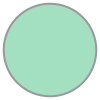

In [ ]:
area_of_influence = point.buffer(1)
print(area_of_influence.geom_type, round(area_of_influence.area, 3))  # ≈ π, it is a polygonal approximation of a circle
area_of_influence

Relaciones espaciales (devuelven `True`/`False`) y distancia. Son las mismas que luego aplicarás en GeoPandas sobre columnas enteras y en *spatial joins*.

In [ ]:
other = Point(2.5, 4.5)

print(area_of_influence.contains(other))  # is the point inside the buffer?
print(other.within(area_of_influence))    # same question, from the other side
print(point.distance(other))              # Euclidean distance

True
True
0.4242640687119283


## ⚠️ Unidades: por qué el TFG trabaja en EPSG:25830

`length`, `area`, `distance` y `buffer` usan **las unidades de las coordenadas**. Si las coordenadas son longitud/latitud (EPSG:4326), el resultado sale en **grados**, que no son una unidad de distancia útil (un grado de longitud no mide lo mismo en Asturias que en el ecuador).

Ejemplo con Oviedo y Gijón. Las coordenadas en EPSG:25830 (UTM 30N, en metros) se han obtenido reproyectando las de EPSG:4326; cómo se hace eso se ve más adelante en el libro.

In [ ]:
# Approximate city centres
oviedo_lonlat, gijon_lonlat = Point(-5.8448, 43.3614), Point(-5.6615, 43.5453)  # EPSG:4326 (degrees)
oviedo_utm, gijon_utm = Point(269483, 4804880), Point(284990, 4824814)          # EPSG:25830 (metres)

print(f"In degrees: {oviedo_lonlat.distance(gijon_lonlat):.4f}  <- meaningless as a distance")
print(f"In metres:  {oviedo_utm.distance(gijon_utm):,.0f} m (straight line)")

In degrees: 0.2596  <- meaningless as a distance
In metres:  25,255 m (straight line)


**Regla para el TFG:** pasar todo a EPSG:25830 antes de medir o hacer buffers. Así `buffer(5000)` significa 5 km.

## Lo que se ha omitido del capítulo
- Polígonos con huecos (`Polygon(shell, holes)`): existen, pero no se crean a mano en el TFG.
- `shapely.box(minx, miny, maxx, maxy)`: crea un rectángulo; útil para recortar una zona de interés si hiciera falta.
- `.coords` como `CoordinateSequence`, `line.xy`, puntos 3D (`POINT Z`): detalles que GeoPandas ya resuelve.

Documentación: https://shapely.readthedocs.io/

## Ejercicio (del libro)
Crea un triángulo, un cuadrado y un círculo.

In [ ]:
from shapely import Point, Polygon

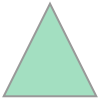

In [8]:
triangle = Polygon([(0, 0), (2, 0), (1, 2)])
triangle

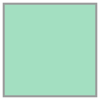

In [10]:
square = Polygon([(0, 0), (2, 0), (2, 2), (0, 2)])
square

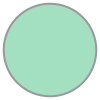

In [12]:

circle = Point(0, 0).buffer(1)
circle